# COVID analysis — starter notebook

Works on `covid-combo.db` (SQLite). Tables:

| Table | Source | What |
|---|---|---|
| `covid_data` | OWID `owid-covid-data.csv` | cases, deaths, excess mortality, vaccination, demographics per country/day |
| `vaccinations_by_manufacturer` | OWID `vaccinations-by-manufacturer.csv` | cumulative doses per vaccine, 44 countries |
| `locations` | OWID `locations.csv` | which vaccines each country used (no counts) |
| `ve_primary_series` | IVAC VIEW-hub | vaccine-effectiveness estimates from published studies, primary series |
| `ve_booster` | IVAC VIEW-hub | same, for boosters |

Kernel: **syntra-ds**.

In [21]:
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

conn = sqlite3.connect("covid-combo.db")


def sql(query: str, **kwargs) -> pd.DataFrame:
    """Run a query against covid-combo.db and return a DataFrame."""
    return pd.read_sql(query, conn, **kwargs)

In [22]:
# Tables and row counts
tables = sql("SELECT name FROM sqlite_master WHERE type='table'").name
pd.DataFrame({
    "table": tables,
    "rows": [sql(f"SELECT COUNT(*) n FROM {t}").n[0] for t in tables],
})

,table,rows
0,covid_data,429435
1,vaccinations_by_manufacturer,68509
2,locations,223
3,ve_primary_series,4276
4,ve_booster,3740
5,gdp_annual,4176
6,gdp_covid_loss,247


In [23]:
# Columns of the main table
sql("PRAGMA table_info(covid_data)")[["name", "type"]].T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,...,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66
name,iso_code,continent,location,date,total_cases,new_cases,new_cases_smoothed,total_deaths,new_deaths,new_deaths_smoothed,total_cases_per_million,new_cases_per_million,new_cases_smoothed_per_million,total_deaths_per_million,new_deaths_per_million,new_deaths_smoothed_per_million,reproduction_rate,icu_patients,icu_patients_per_million,hosp_patients,hosp_patients_per_million,weekly_icu_admissions,weekly_icu_admissions_per_million,weekly_hosp_admissions,weekly_hosp_admissions_per_million,...,people_fully_vaccinated_per_hundred,total_boosters_per_hundred,new_vaccinations_smoothed_per_million,new_people_vaccinated_smoothed,new_people_vaccinated_smoothed_per_hundred,stringency_index,population_density,median_age,aged_65_older,aged_70_older,gdp_per_capita,extreme_poverty,cardiovasc_death_rate,diabetes_prevalence,female_smokers,male_smokers,handwashing_facilities,hospital_beds_per_thousand,life_expectancy,human_development_index,population,excess_mortality_cumulative_absolute,excess_mortality_cumulative,excess_mortality,excess_mortality_cumulative_per_million
type,TEXT,TEXT,TEXT,TIMESTAMP,REAL,REAL,REAL,REAL,REAL,REAL,REAL,REAL,REAL,REAL,REAL,REAL,REAL,REAL,REAL,REAL,REAL,REAL,REAL,REAL,REAL,...,REAL,REAL,REAL,REAL,REAL,REAL,REAL,REAL,REAL,REAL,REAL,REAL,REAL,REAL,REAL,REAL,REAL,REAL,REAL,REAL,INTEGER,REAL,REAL,REAL,REAL


## 1. One country over time

Change `COUNTRIES` to compare others.

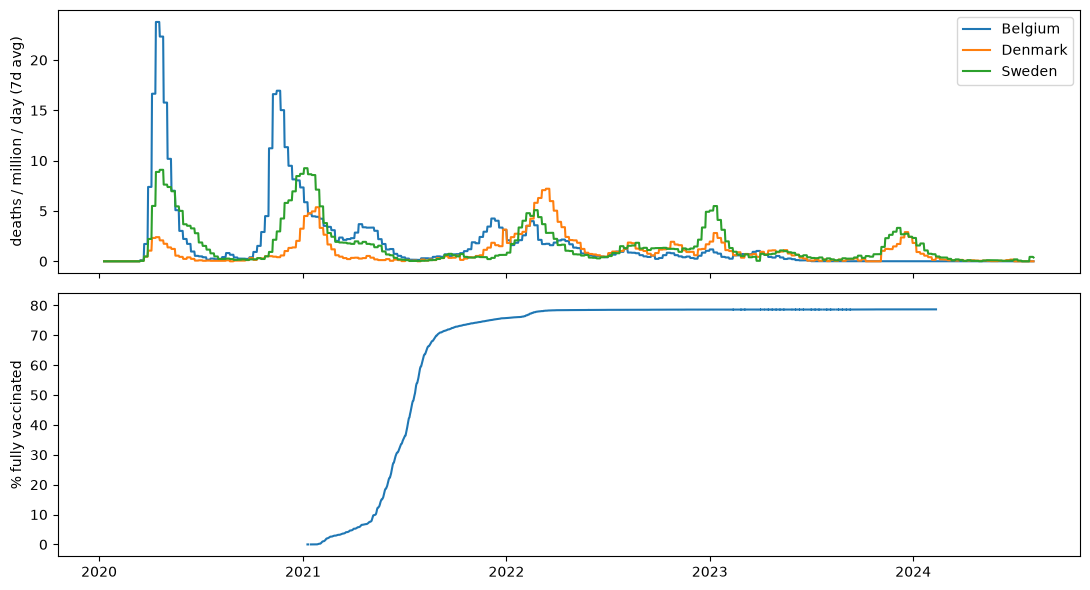

In [24]:
COUNTRIES = ("Belgium", "Denmark", "Sweden")

placeholders = ",".join("?" * len(COUNTRIES))
ts = sql(f"""
    SELECT location, date, new_deaths_smoothed_per_million,
           people_fully_vaccinated_per_hundred, excess_mortality
    FROM covid_data
    WHERE location IN ({placeholders})
""", params=COUNTRIES, parse_dates=["date"])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for loc, g in ts.groupby("location"):
    ax1.plot(g.date, g.new_deaths_smoothed_per_million, label=loc)
    ax2.plot(g.date, g.people_fully_vaccinated_per_hundred, label=loc)
ax1.set_ylabel("deaths / million / day (7d avg)")
ax2.set_ylabel("% fully vaccinated")
ax1.legend()
plt.tight_layout()

## 2. Which countries dealt best with COVID?

Measure: **cumulative excess mortality per million, 2020 → end 2022** — counts all extra deaths,
so it isn't fooled by countries that tested or reported poorly.

Filters: population ≥ 1M, last excess-mortality value between 2022-10-01 and 2022-12-31.
Coverage is mostly richer/middle-income countries (Africa, India, China largely missing).

In [25]:
CUTOFF = "2022-12-31"
MIN_POP = 1_000_000

ranking = sql("""
WITH em AS (
  SELECT location, date, excess_mortality_cumulative_per_million AS excess_pm,
         ROW_NUMBER() OVER (PARTITION BY location ORDER BY date DESC) AS rn
  FROM covid_data
  WHERE excess_mortality_cumulative_per_million IS NOT NULL
    AND iso_code NOT LIKE 'OWID_%' AND date <= :cutoff),
rep AS (
  SELECT location, MAX(total_deaths_per_million) AS reported_pm
  FROM covid_data WHERE date <= :cutoff GROUP BY location),
st AS (
  SELECT location, MAX(continent) AS continent, MAX(population) AS population,
         MAX(aged_65_older) AS pct_65plus, MAX(gdp_per_capita) AS gdp_per_capita,
         MAX(people_fully_vaccinated_per_hundred) AS pct_fully_vax,
         AVG(stringency_index) AS avg_stringency
  FROM covid_data WHERE date <= :cutoff GROUP BY location)
SELECT em.location, st.continent, date(em.date) AS last_date,
       em.excess_pm, rep.reported_pm, st.population, st.pct_65plus,
       st.gdp_per_capita, st.pct_fully_vax, st.avg_stringency
FROM em JOIN rep USING (location) JOIN st USING (location)
WHERE em.rn = 1 AND em.date >= date(:cutoff, '-3 months') AND st.population >= :min_pop
ORDER BY em.excess_pm
""", params={"cutoff": CUTOFF, "min_pop": MIN_POP})

ranking["excess_vs_reported"] = ranking.excess_pm / ranking.reported_pm
print(f"{len(ranking)} countries")
ranking.head(15).round(1)

81 countries


,location,continent,last_date,excess_pm,reported_pm,population,pct_65plus,gdp_per_capita,pct_fully_vax,avg_stringency,excess_vs_reported
0,New Zealand,Oceania,2022-12-25,-83.3,445.8,5185289,15.3,36085.8,79.8,34.8,-0.2
1,Mongolia,Asia,2022-11-30,193.3,630.8,3398373,4.0,11840.8,64.0,43.1,0.3
2,Qatar,Asia,2022-11-30,510.2,236.8,2695131,1.3,116935.6,105.8,52.7,2.2
3,Japan,Asia,2022-11-30,658.0,446.5,123951696,27.0,39002.2,83.2,40.5,1.5
4,Denmark,Europe,2022-12-25,675.0,1306.5,5882259,19.7,46682.5,80.1,35.5,0.5
5,Dominican Republic,North America,2022-11-30,720.6,390.4,11228821,7.0,14600.9,54.1,45.2,1.8
6,Taiwan,Asia,2022-11-30,727.6,NaN,23893396,NaN,NaN,86.3,30.2,NaN
7,Australia,Oceania,2022-12-25,919.7,680.0,26177410,15.5,44648.7,82.7,47.4,1.4
8,Singapore,Asia,2022-11-30,923.4,302.8,5637022,12.9,85535.4,90.7,43.7,3.0
9,Oman,Asia,2022-11-30,976.6,978.4,4576300,2.4,37960.7,66.6,46.5,1.0


In [26]:
# Worst 15
ranking.tail(15).iloc[::-1].round(1)

,location,continent,last_date,excess_pm,reported_pm,population,pct_65plus,gdp_per_capita,pct_fully_vax,avg_stringency,excess_vs_reported
80,Bulgaria,Europe,2022-12-25,10166.0,5572.3,6781955,20.8,18563.3,30.6,36.3,1.8
79,Russia,Europe,2022-11-30,8567.8,2702.2,144713312,14.2,24766.0,54.5,41.4,3.2
78,Serbia,Europe,2022-11-30,8474.6,2576.1,6871547,17.4,14048.9,47.7,37.5,3.3
77,Lithuania,Europe,2022-12-25,8358.0,3361.5,2750058,19.0,29524.3,68.4,36.2,2.5
76,Armenia,Asia,2022-11-30,8061.2,3022.7,2780472,11.2,8787.6,35.4,NaN,2.7
75,North Macedonia,Europe,2022-11-30,7955.3,5366.7,2093606,13.3,13111.2,40.0,NaN,1.5
74,Bosnia and Herzegovina,Europe,2022-11-30,7065.6,5061.8,3233530,16.6,11713.9,26.2,38.8,1.4
73,Georgia,Asia,2022-11-30,6901.7,4453.0,3744385,14.9,9745.1,34.1,43.7,1.5
72,Peru,South America,2022-10-09,5901.3,6512.4,34049588,7.2,12236.7,83.5,53.9,0.9
71,Romania,Europe,2022-12-25,5864.2,3513.4,19659270,17.8,23313.2,41.3,44.5,1.7


In [27]:
# What goes together with low excess mortality? (correlation, not causation)
ranking[["excess_pm", "pct_fully_vax", "gdp_per_capita", "pct_65plus", "avg_stringency"]] \
    .corr().loc["excess_pm"].round(2)

excess_pm         1.00
pct_fully_vax    -0.47
gdp_per_capita   -0.38
pct_65plus        0.19
avg_stringency   -0.02
Name: excess_pm, dtype: float64

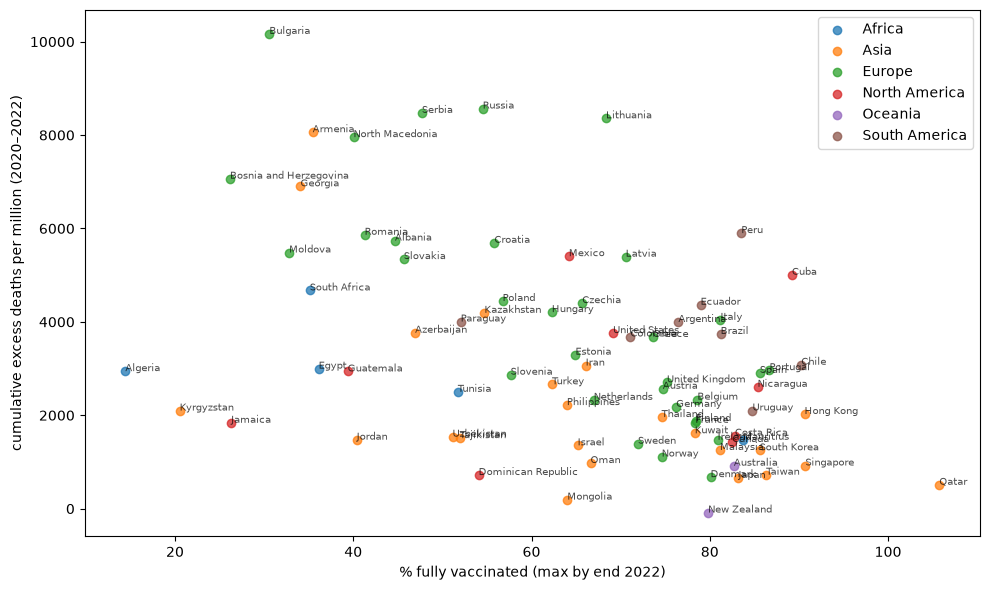

In [28]:
# Excess mortality vs. vaccination rate
fig, ax = plt.subplots(figsize=(10, 6))
for cont, g in ranking.groupby("continent"):
    ax.scatter(g.pct_fully_vax, g.excess_pm, label=cont, alpha=0.75)
for _, r in ranking.iterrows():
    ax.annotate(r.location, (r.pct_fully_vax, r.excess_pm), fontsize=7, alpha=0.7)
ax.set_xlabel("% fully vaccinated (max by end 2022)")
ax.set_ylabel("cumulative excess deaths per million (2020–2022)")
ax.legend()
plt.tight_layout()

### Rough age adjustment

Older populations are expected to have more deaths. A simple linear fit of excess mortality on % aged 65+
gives an "expected" value; `vs_expected < 0` means better than expected.
This is a crude correction (the fit explains little) — proper age-standardised data would be fairer.

In [29]:
m = ranking.dropna(subset=["pct_65plus"])
slope, intercept = np.polyfit(m.pct_65plus, m.excess_pm, 1)
ranking["vs_expected"] = ranking.excess_pm - (intercept + slope * ranking.pct_65plus)
print(f"expected excess_pm = {intercept:.0f} + {slope:.0f} × %65+   "
      f"(corr = {np.corrcoef(m.pct_65plus, m.excess_pm)[0, 1]:.2f})")
ranking.sort_values("vs_expected")[["location", "excess_pm", "pct_65plus", "vs_expected"]].head(12).round(0)

expected excess_pm = 2434 + 67 × %65+   (corr = 0.19)


,location,excess_pm,pct_65plus,vs_expected
3,Japan,658.0,27.0,-3596.0
0,New Zealand,-83.0,15.0,-3548.0
4,Denmark,675.0,20.0,-3083.0
7,Australia,920.0,16.0,-2557.0
1,Mongolia,193.0,4.0,-2512.0
10,Norway,1116.0,17.0,-2450.0
14,Sweden,1390.0,20.0,-2389.0
8,Singapore,923.0,13.0,-2380.0
5,Dominican Republic,721.0,7.0,-2183.0
15,Canada,1426.0,17.0,-2151.0


## 3. Which vaccine worked best? (VIEW-hub)

Each row in `ve_primary_series` is one VE estimate (%) with a 95% CI from one study.
We look at **death**, **completed primary series** (`dose = 'final'`), and split by variant period,
because Omicron lowered VE for every vaccine and different vaccines were studied in different periods.

In [30]:
ve = sql("""
    SELECT study_id, first_author, primary_series_vaccine AS vaccine, country,
           population_category, variant_context, ve, lcl, ucl
    FROM ve_primary_series
    WHERE outcome_category = 'death' AND dose = 'final'
      AND primary_series_vaccine NOT LIKE '% vs %'   -- relative comparisons, not VE vs. unvaccinated
      AND ve IS NOT NULL
""")


def variant_period(v) -> str:
    if v is None or pd.isna(v):
        return "unknown"
    v = v.lower()
    if v.startswith("omicron"):
        return "omicron"
    return "mixed" if "omicron" in v else "pre-omicron"


ve["period"] = ve.variant_context.map(variant_period)
ve.period.value_counts()

period
pre-omicron    257
omicron         58
mixed           48
Name: count, dtype: int64

In [31]:
# Crude summary: plain average of all estimates
(ve.groupby(["period", "vaccine"])
   .agg(estimates=("ve", "size"), studies=("study_id", "nunique"),
        countries=("country", "nunique"), avg_ve=("ve", "mean"))
   .query("studies >= 3")
   .round(1)
   .sort_values(["period", "avg_ve"], ascending=[True, False]))

estimates  studies  countries  avg_ve
period      vaccine                                                                                 
mixed       mRNA-1273 (Moderna)                                        3        3          2    96.2
            CoronaVac (Sinovac)                                        5        5          3    84.4
            BNT162b2 (Pfizer BioNTech)                                18        8          5    65.4
            AZD1222 (AstraZeneca)                                     19        6          3    54.9
omicron     CoronaVac (Sinovac)                                       13        7          2    73.7
            BNT162b2 (Pfizer BioNTech)                                22       10          4    67.3
            BNT162b2 (Pfizer BioNTech) or mRNA-1273 (Moderna)          7        5          5    66.2
pre-omicron mRNA-1273 (Moderna)                                       34       14          9    92.7
            BNT162b2 (Pfizer BioNTech) or mRNA-1273 (Moderna)         18       11          6    88.9
            BNT162b2 (Pfizer BioNTech)                                68       30         17    87.8
            AZD1222 (AstraZeneca)                                     50       21         13    83.5
            Gam-COVID-Vac (Gamaleya)                                  13        7          4    83.2
            Ad5-nCOV (CanSino)                                         6        3          1    82.5
            Ad26.COV2.S (Janssen)                                     31       13         10    80.6
            CoronaVac (Sinovac)                                       14       10          5    71.0
            BBIBP-CorV (Beijing CNBG)                                 19        8          6    65.9

### Weighted (inverse-variance) pooled VE

Standard meta-analysis approach: work on the log relative-risk scale, `log(1 − VE)`,
derive the standard error from the CI, and weight each estimate by `1 / SE²`
so precise studies count more. This is a simple **fixed-effect** pool that treats estimates as independent —
several come from the same study, so the CIs are too narrow. Good for a ranking, not for publication.

In [32]:
def pooled_ve(df: pd.DataFrame) -> pd.Series:
    d = df.dropna(subset=["ve", "lcl", "ucl"])
    d = d[(d.ve < 100) & (d.ucl < 100) & (d.lcl < d.ucl)]
    log_rr = np.log(1 - d.ve / 100)
    se = (np.log(1 - d.lcl / 100) - np.log(1 - d.ucl / 100)) / (2 * 1.96)
    w = 1 / se**2
    est = (w * log_rr).sum() / w.sum()
    se_pooled = np.sqrt(1 / w.sum())
    return pd.Series({
        "estimates": len(d),
        "studies": d.study_id.nunique(),
        "pooled_ve": 100 * (1 - np.exp(est)),
        "ci_low": 100 * (1 - np.exp(est + 1.96 * se_pooled)),
        "ci_high": 100 * (1 - np.exp(est - 1.96 * se_pooled)),
    })


pooled = (ve.groupby(["period", "vaccine"])[["study_id", "ve", "lcl", "ucl"]]
            .apply(pooled_ve)
            .query("studies >= 3")
            .round(1)
            .sort_values(["period", "pooled_ve"], ascending=[True, False]))
pooled

estimates  studies  pooled_ve  ci_low  ci_high
period      vaccine                                                                                          
mixed       mRNA-1273 (Moderna)                                      3.0      3.0       95.8    94.0     97.1
            CoronaVac (Sinovac)                                      5.0      5.0       85.6    85.2     86.1
            BNT162b2 (Pfizer BioNTech)                              18.0      8.0       82.4    81.2     83.6
            AZD1222 (AstraZeneca)                                   18.0      6.0       71.9    69.4     74.1
omicron     BNT162b2 (Pfizer BioNTech)                              22.0     10.0       78.7    77.1     80.1
            BNT162b2 (Pfizer BioNTech) or mRNA-1273 (Moderna)        7.0      5.0       71.6    69.6     73.5
            CoronaVac (Sinovac)                                     13.0      7.0       69.9    68.8     70.9
pre-omicron Gam-COVID-Vac (Gamaleya)                                13.0      7.0       91.9    91.5     92.3
            mRNA-1273 (Moderna)                                     29.0     13.0       91.6    90.8     92.4
            BNT162b2 (Pfizer BioNTech)                              65.0     29.0       88.8    88.5     89.1
            AZD1222 (AstraZeneca)                                   49.0     21.0       86.7    86.2     87.1
            BNT162b2 (Pfizer BioNTech) or mRNA-1273 (Moderna)       14.0      9.0       86.4    84.6     88.0
            Ad26.COV2.S (Janssen)                                   30.0     13.0       82.0    80.3     83.6
            Ad5-nCOV (CanSino)                                       5.0      3.0       79.1    77.7     80.4
            BBIBP-CorV (Beijing CNBG)                               18.0      8.0       78.6    77.5     79.7
            CoronaVac (Sinovac)                                     14.0     10.0       77.0    76.4     77.6

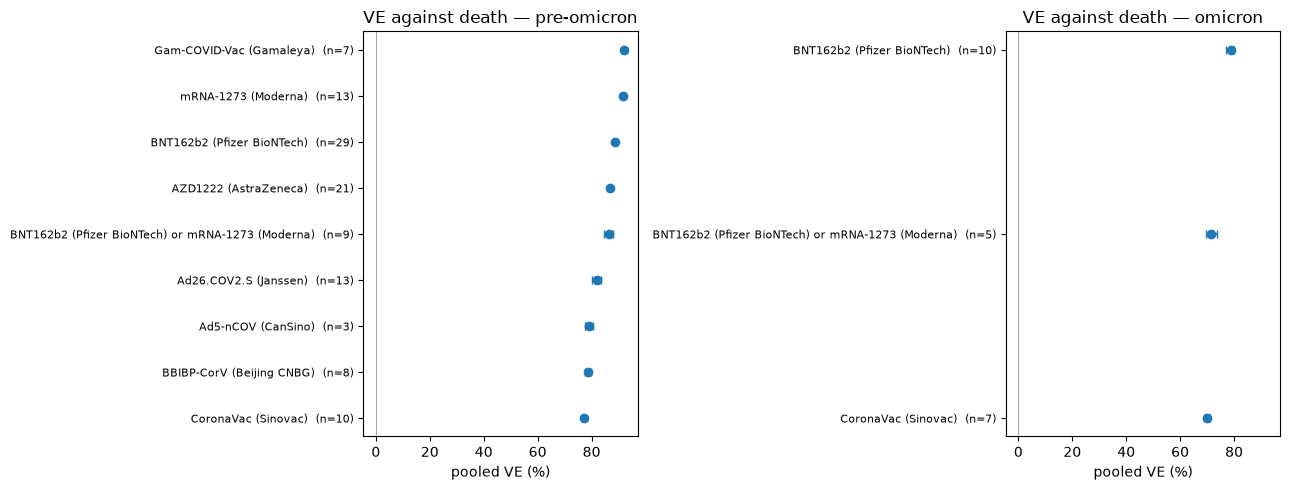

In [33]:
# Forest-style plot per period
periods = [p for p in ("pre-omicron", "omicron") if p in pooled.index.get_level_values(0)]
fig, axes = plt.subplots(1, len(periods), figsize=(13, 5), sharex=True)
for ax, p in zip(np.atleast_1d(axes), periods):
    d = pooled.loc[p].sort_values("pooled_ve")
    ax.errorbar(d.pooled_ve, range(len(d)),
                xerr=[d.pooled_ve - d.ci_low, d.ci_high - d.pooled_ve], fmt="o", capsize=3)
    ax.set_yticks(range(len(d)), [f"{v}  (n={int(s)})" for v, s in zip(d.index, d.studies)], fontsize=8)
    ax.set_title(f"VE against death — {p}")
    ax.set_xlabel("pooled VE (%)")
    ax.axvline(0, color="grey", lw=0.5)
plt.tight_layout()

In [34]:
# Drill down: all death estimates for one vaccine
VACCINE = "CoronaVac (Sinovac)"
ve[ve.vaccine == VACCINE].sort_values("ve")

,study_id,first_author,vaccine,country,population_category,variant_context,ve,lcl,ucl,period
171,279,Paternina-Caicedo,CoronaVac (Sinovac),Colombia,≥ 40 years,mu,20.6,-0.5,37.3,pre-omicron
280,426,Hernandez-Avila,CoronaVac (Sinovac),Mexico,≥65 years,delta,59.2,51.6,65.5,pre-omicron
286,428,Yiu,CoronaVac (Sinovac),"Hong Kong, SAR",≥18 years with a mental disorder,omicron BA.2,59.5,53.7,64.6,omicron
2,32,Ranzani,CoronaVac (Sinovac),Brazil,≥ 70 years,gamma,61.2,48.9,70.5,pre-omicron
173,285,Cerqueira-Silva,CoronaVac (Sinovac),Brazil,general pop,omicron,63.1,60.9,65.1,omicron
84,137,Castillo-Arregoces,CoronaVac (Sinovac),Colombia,60+ years,mu,64.9,61.2,68.9,pre-omicron
172,285,Cerqueira-Silva,CoronaVac (Sinovac),Brazil,general pop,omicron,67.8,64.0,71.3,omicron
214,332,Wan,CoronaVac (Sinovac),"Hong Kong, SAR",≥80 years,omicron BA.2,69.4,65.6,72.8,omicron
26,107,Arregoces,CoronaVac (Sinovac),Colombia,≥ 60 years,mu,69.8,66.7,72.6,pre-omicron
180,298,Cheng,CoronaVac (Sinovac),"Hong Kong, SAR",patients with chronic kidney disease,omicron,70.0,64.0,75.0,omicron


## 4. Vaccine mix per country (OWID manufacturer data, 44 countries)

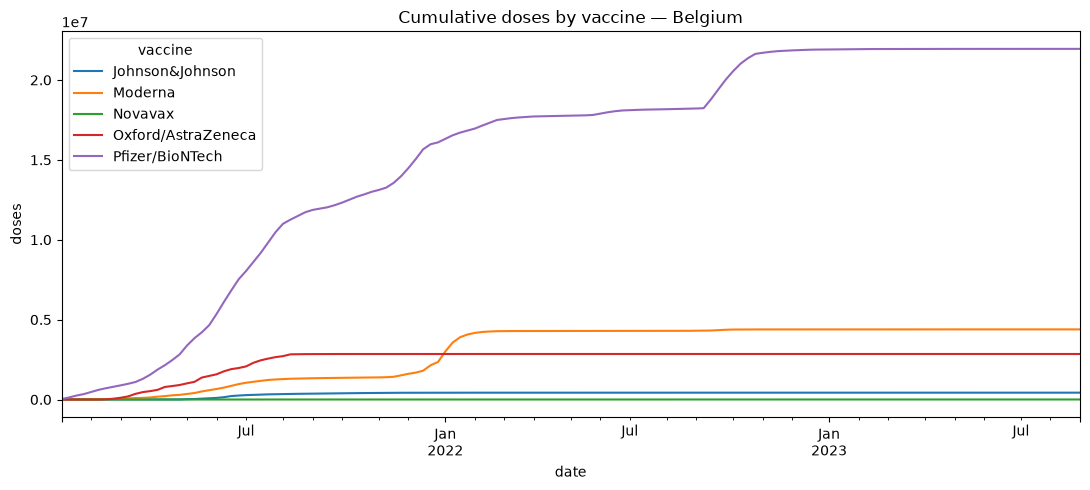

In [35]:
COUNTRY = "Belgium"
mix = sql("""
    SELECT date, vaccine, total_vaccinations
    FROM vaccinations_by_manufacturer WHERE location = ?
""", params=(COUNTRY,), parse_dates=["date"])

mix.pivot_table(index="date", columns="vaccine", values="total_vaccinations") \
   .ffill().plot(figsize=(11, 5), title=f"Cumulative doses by vaccine — {COUNTRY}")
plt.ylabel("doses")
plt.tight_layout()

In [36]:
# Final share of doses per vaccine, per country
latest = sql("""
    SELECT location, vaccine, MAX(total_vaccinations) AS doses
    FROM vaccinations_by_manufacturer GROUP BY location, vaccine
""")
share = latest.pivot_table(index="location", columns="vaccine", values="doses", fill_value=0)
(share.div(share.sum(axis=1), axis=0) * 100).round(1)

vaccine,CanSino,Covaxin,Johnson&Johnson,Medicago,Moderna,Novavax,Oxford/AstraZeneca,Pfizer/BioNTech,SKYCovione,Sanofi/GSK,Sinopharm/Beijing,Sinovac,Sputnik Light,Sputnik V,Valneva
location,,,,,,,,,,,,,,,
Argentina,0.8,0.0,0.0,0.0,16.0,0.0,22.9,17.7,0.0,0.0,24.8,0.0,0.0,17.7,0.0
Austria,0.0,0.0,1.8,0.0,8.1,0.1,7.8,82.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Belgium,0.0,0.0,1.4,0.0,14.8,0.0,9.6,74.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Bulgaria,0.0,0.0,11.5,0.0,11.1,0.0,10.4,67.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Canada,0.0,0.0,0.0,0.0,30.3,0.0,3.0,66.7,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Chile,0.0,0.0,0.0,0.0,0.0,0.0,1.6,23.3,0.0,0.0,0.0,75.1,0.0,0.0,0.0
Croatia,0.0,0.0,3.8,0.0,9.7,0.0,10.5,75.9,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Cyprus,0.0,0.0,1.7,0.0,11.1,0.1,14.2,72.9,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Czechia,0.0,0.0,2.2,0.0,8.6,0.1,4.7,84.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 5. Which vaccines did each country use? (`locations`, all countries, no counts)

In [37]:
locs = sql("SELECT location, iso_code, vaccines FROM locations")
long = locs.assign(vaccine=locs.vaccines.str.split(",\\s*")).explode("vaccine")
long.vaccine.value_counts().head(15)

vaccine
Oxford/AstraZeneca    187
Pfizer/BioNTech       167
Moderna               115
Johnson&Johnson       106
Sinopharm/Beijing      96
Sinovac                67
Sputnik V              67
Novavax                33
Covaxin                31
Sputnik Light          29
CanSino                27
Sanofi/GSK              4
Abdala                  4
Soberana02              4
Sinopharm/Wuhan         3
Name: count, dtype: int64

## 6. Who coped best? Deaths vs. economic cost

Three dimensions per country:

- **y — health:** cumulative excess deaths per million up to `EM_CUTOFF` (end 2023 by default, so
  countries that only *postponed* deaths — e.g. NZ, Australia — are judged fairly)
- **x — economy:** cumulative GDP loss 2020–2023 vs. the 2015–2019 trend (`gdp_covid_loss`)
- **colour — restrictions:** average `stringency_index` 2020–2022 (how much lockdown it took)

**Bottom-left = few deaths at low economic cost.** Dashed lines are the medians of the plotted group.
GDP loss also contains non-COVID shocks (energy crisis 2022, wars, oil booms) — use `PEER_GROUP`
to compare similar countries, and `MAX_ABS_GDP_LOSS` to drop extreme outliers.

In [38]:
EM_CUTOFF = "2023-12-31"        # excess mortality measured up to this date
EM_MAX_STALENESS = "-6 months"  # last excess-mortality value must be within this window of EM_CUTOFF
MIN_POP = 1_000_000
MAX_ABS_GDP_LOSS = 25           # drop countries whose GDP "loss" is dominated by other shocks
PEER_GROUP = None               # e.g. ["Europe"] (continents) or None for all

coped = sql("""
WITH em AS (
  SELECT location, iso_code, date, excess_mortality_cumulative_per_million AS excess_pm,
         ROW_NUMBER() OVER (PARTITION BY location ORDER BY date DESC) AS rn
  FROM covid_data
  WHERE excess_mortality_cumulative_per_million IS NOT NULL
    AND iso_code NOT LIKE 'OWID_%' AND date <= :cutoff),
st AS (
  SELECT location, MAX(continent) AS continent, MAX(population) AS population,
         MAX(aged_65_older) AS pct_65plus,
         MAX(people_fully_vaccinated_per_hundred) AS pct_fully_vax,
         AVG(CASE WHEN date < '2023-01-01' THEN stringency_index END) AS avg_stringency
  FROM covid_data GROUP BY location)
SELECT em.location, em.iso_code, st.continent, date(em.date) AS em_last_date, em.excess_pm,
       g.cum_loss_2020_2023_pct_of_trend AS gdp_loss_pct, g.growth_2020_pct,
       st.avg_stringency, st.pct_fully_vax, st.pct_65plus, st.population
FROM em
JOIN st USING (location)
JOIN gdp_covid_loss g ON g.iso_code = em.iso_code
WHERE em.rn = 1
  AND em.date >= date(:cutoff, :stale)
  AND st.population >= :min_pop
""", params={"cutoff": EM_CUTOFF, "stale": EM_MAX_STALENESS, "min_pop": MIN_POP})

dropped = coped[coped.gdp_loss_pct.abs() > MAX_ABS_GDP_LOSS].location.tolist()
coped = coped[coped.gdp_loss_pct.abs() <= MAX_ABS_GDP_LOSS]
if PEER_GROUP:
    coped = coped[coped.continent.isin(PEER_GROUP)]
print(f"{len(coped)} countries plotted; dropped as GDP outliers: {dropped or 'none'}")
coped.sort_values("excess_pm").head(10).round(1)

67 countries plotted; dropped as GDP outliers: none


,location,iso_code,continent,em_last_date,excess_pm,gdp_loss_pct,growth_2020_pct,avg_stringency,pct_fully_vax,pct_65plus,population
38,Mongolia,MNG,Asia,2023-11-30,-21.6,11.0,-4.6,43.1,64.0,4.0,3398373
40,New Zealand,NZL,Oceania,2023-12-24,94.5,2.8,-0.2,34.8,82.8,15.3,5185289
16,Dominican Republic,DOM,North America,2023-10-31,644.1,8.6,-7.9,45.2,54.6,7.0,11228821
49,Qatar,QAT,Asia,2023-11-30,671.3,2.1,-3.6,52.7,105.8,1.3,2695131
43,Oman,OMN,Asia,2023-11-30,787.3,0.6,-3.4,46.5,66.6,2.4,4576300
15,Denmark,DNK,Europe,2023-12-24,954.7,2.6,-1.8,35.4,80.1,19.7,5882259
36,Malaysia,MYS,Asia,2023-11-30,1275.6,9.4,-5.5,49.4,81.2,6.3,33938216
3,Australia,AUS,Oceania,2023-12-24,1375.0,1.9,-0.1,47.4,82.7,15.5,26177410
53,Singapore,SGP,Asia,2023-11-30,1476.7,1.7,-3.6,43.7,90.8,12.9,5637022
32,Kuwait,KWT,Asia,2023-11-30,1485.3,2.6,-4.8,48.7,78.4,2.4,4268886


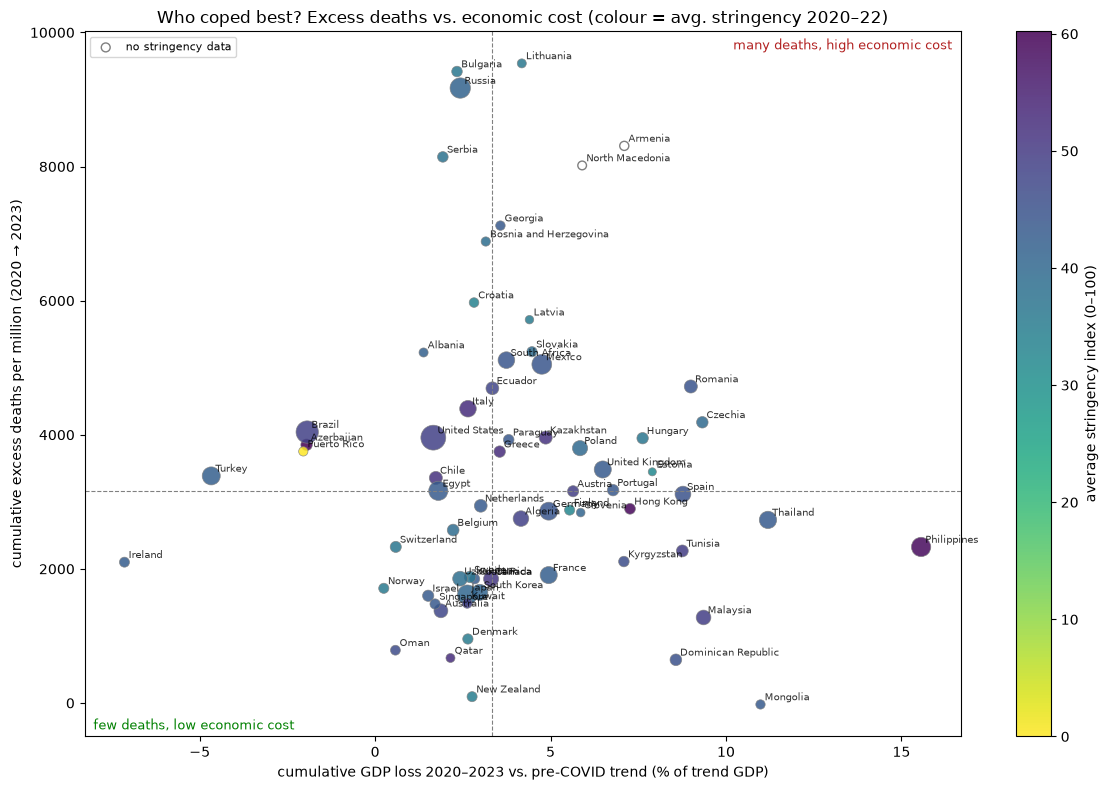

In [39]:
fig, ax = plt.subplots(figsize=(12, 8))
size = np.sqrt(coped.population) / 60 + 15  # dot size ~ population
has_s = coped.avg_stringency.notna()
sc = ax.scatter(coped.gdp_loss_pct[has_s], coped.excess_pm[has_s], c=coped.avg_stringency[has_s],
                cmap="viridis_r", s=size[has_s], alpha=0.85, edgecolors="grey", linewidths=0.5)
ax.scatter(coped.gdp_loss_pct[~has_s], coped.excess_pm[~has_s], s=size[~has_s],
           facecolors="none", edgecolors="grey", label="no stringency data")
if (~has_s).any():
    ax.legend(loc="upper left", fontsize=8)
for _, r in coped.iterrows():
    ax.annotate(r.location, (r.gdp_loss_pct, r.excess_pm), fontsize=7, alpha=0.8,
                xytext=(3, 3), textcoords="offset points")

ax.axvline(coped.gdp_loss_pct.median(), color="grey", ls="--", lw=0.8)
ax.axhline(coped.excess_pm.median(), color="grey", ls="--", lw=0.8)
ax.text(0.01, 0.01, "few deaths, low economic cost", transform=ax.transAxes, color="green", fontsize=9)
ax.text(0.99, 0.99, "many deaths, high economic cost", transform=ax.transAxes, color="firebrick",
        fontsize=9, ha="right", va="top")

ax.set_xlabel("cumulative GDP loss 2020–2023 vs. pre-COVID trend (% of trend GDP)")
ax.set_ylabel(f"cumulative excess deaths per million (2020 → {EM_CUTOFF[:4]})")
ax.set_title("Who coped best? Excess deaths vs. economic cost (colour = avg. stringency 2020–22)")
fig.colorbar(sc, ax=ax, label="average stringency index (0–100)")
plt.tight_layout()

### Combined ranking (equal weights)

Rank each country on excess deaths and on GDP loss (1 = best), then average the two ranks.
The weights are a choice — change `W_HEALTH` and check whether the top of the list is stable.

In [40]:
W_HEALTH = 0.5  # 0.5 = health and economy count equally

ranked = coped.assign(
    rank_health=coped.excess_pm.rank(),
    rank_economy=coped.gdp_loss_pct.rank(),
)
ranked["combined_score"] = W_HEALTH * ranked.rank_health + (1 - W_HEALTH) * ranked.rank_economy
ranked = ranked.sort_values("combined_score")
cols = ["location", "continent", "excess_pm", "gdp_loss_pct", "avg_stringency", "pct_fully_vax",
        "rank_health", "rank_economy", "combined_score"]
ranked[cols].head(15).round(1)

,location,continent,excess_pm,gdp_loss_pct,avg_stringency,pct_fully_vax,rank_health,rank_economy,combined_score
43,Oman,Asia,787.3,0.6,46.5,66.6,5.0,7.0,6.0
42,Norway,Europe,1710.3,0.2,35.8,74.6,14.0,6.0,10.0
27,Ireland,Europe,2100.2,-7.1,42.7,80.9,20.0,1.0,10.5
28,Israel,Asia,1599.4,1.5,43.4,65.2,11.0,10.0,10.5
49,Qatar,Asia,671.3,2.1,52.7,105.8,4.0,17.0,10.5
53,Singapore,Asia,1476.7,1.7,43.7,90.8,9.0,12.0,10.5
3,Australia,Oceania,1375.0,1.9,47.4,82.7,8.0,15.0,11.5
40,New Zealand,Oceania,94.5,2.8,34.8,82.8,2.0,27.0,14.5
15,Denmark,Europe,954.7,2.6,35.4,80.1,6.0,24.0,15.0
60,Switzerland,Europe,2328.0,0.6,36.5,NaN,24.0,8.0,16.0


In [20]:
# Worst 10 on the combined score
ranked[cols].tail(10).iloc[::-1].round(1)

NameError: name 'ranked' is not defined

In [ ]:
conn.close()